# ETF Cluster Evaluation — leave-one-experiment-out fine-tuning

Evaluates a `finetune_loo.py` run (`Saved/finetune_<run_id>/`): one fine-tuned
checkpoint per experiment, each trained on **all other experiments** and scored
here on the experiment it never saw. Every row of the tables below is therefore
an honest "new deployment" number from its own fold model.

1. Loads `loo_manifest.json` and every fold's checkpoint, config and `_split.csv`.
2. Loads the dataset once, scales each held-out experiment with its fold's
   scalers, and runs that fold's model on it.
3. Reports per-experiment and pooled metrics against the pretrained model (before
   fine-tuning) and a constant baseline (the fold's mean training target).
4. Aligns the per-experiment coordinate systems into one **room frame**
   (`room_alignment.py`) and plots every experiment's centroids, and its true and
   predicted wall hits, together in that frame.

In [14]:
import glob
import importlib
import json
import os
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Locate multitag_ml_training/ so the CWD doesn't matter
HERE = os.path.abspath(".")
while HERE != "/" and not os.path.isfile(os.path.join(HERE, "train_cluster.py")):
    if os.path.isfile(os.path.join(HERE, "multitag_ml_training", "train_cluster.py")):
        HERE = os.path.join(HERE, "multitag_ml_training")
        break
    HERE = os.path.dirname(HERE)
assert os.path.isfile(os.path.join(HERE, "train_cluster.py")), \
    "Could not locate multitag_ml_training/train_cluster.py — launch from inside RFImaging/"
if HERE not in sys.path:
    sys.path.insert(0, HERE)

import train_cluster as _tc
import room_alignment as ra
importlib.reload(_tc)
importlib.reload(ra)
from train_cluster import (SUB_KEYS, load_for_args, load_split, scalers_from_checkpoint)
from MLScripts.models.transformer import TagPairTransformer   # path set up by train_cluster

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("ml dir  :", HERE)
print("T2T_ROOT:", _tc.T2T_ROOT)

ml dir  : /home/manaj/RFImaging/multitag_ml_training
T2T_ROOT: /home/manaj/T2TSionnaSim


## Configuration

`LOO_DIR = None` picks the newest `Saved/finetune_*` folder.

In [15]:
LOO_DIR   = "/home/manaj/RFImaging/multitag_ml_training/Saved/finetune_1020003026"        # None → newest Saved/finetune_* folder
SAVED_DIR = os.path.join(HERE, "Saved")

EVAL_EXPERIMENTS = [10,11,12,14,15,16]  # held-out experiments to evaluate AND plot everywhere below,
                         # e.g. [3, 7, 12]; None → every finished fold

PRED_MAX_CM      = "auto"  # predictions beyond it become NaN; "auto" → dist_clip − 75 cm of the
                           # fine-tune run, or a number [cm], or None to keep everything
EVAL_TRAIN_SPLIT = False  # also score each fold model on its own train split (13× the inference)
VIZ_EXPERIMENTS  = []     # per-experiment visualize_walls3D plots (local frame); [] → skip
VIZ_LIMIT        = 400    # samples drawn per experiment in those plots

ALIGN_REF       = None    # reference experiment of the room frame; None → automatic
ALIGN_RECOMPUTE = False   # redo the scan registration instead of using the cache
MERGED_LIMIT    = 400     # sub-clusters per experiment in the merged wall-hit plot

if LOO_DIR is None:
    _cands = sorted((d for d in glob.glob(os.path.join(SAVED_DIR, "finetune_*"))
                     if os.path.isfile(os.path.join(d, "loo_manifest.json"))),
                    key=os.path.getmtime)
    if not _cands:
        raise FileNotFoundError(
            f"No finetune_* run in {SAVED_DIR}. Start one with\n"
            f"  python multitag_ml_training/finetune_loo.py --model <pretrained>.pth "
            f"--dataset multitag/cluster_features_K10_P1.csv --gpus 0 1 --epochs 30")
    for _d in _cands[-5:]:
        print(f"  {'->' if _d == _cands[-1] else '  '} {os.path.basename(_d)}")
    LOO_DIR = _cands[-1]

with open(os.path.join(LOO_DIR, "loo_manifest.json")) as f:
    manifest = json.load(f)

print(f"\nLOO run   : {LOO_DIR}")
print(f"Pretrained: {manifest['model']}")
print(f"Dataset   : {manifest['dataset']}")
print(f"Forwarded : {' '.join(manifest['forwarded_args']) or '(defaults)'}")
summary = pd.read_csv(os.path.join(LOO_DIR, "loo_summary.csv"))
display(summary.drop(columns=["checkpoint"]))


LOO run   : /home/manaj/RFImaging/multitag_ml_training/Saved/finetune_1020003026
Pretrained: /home/manaj/T2TSionnaSim/MLScripts/Saved/ETF_realistic_45slots_attn_d128_l6_ep300_s42_1014155745.pth
Dataset   : /home/manaj/RFImaging/multitag/cluster_features_K10_P1_new.csv
Forwarded : --epochs 20 --lr 1e-4 --dist_clip 400 --freeze_layers 4


,val_experiment,status,n_train,n_val,best_epoch,pretrained_mae_dist_m,mae_dist_m,pretrained_mae_angle_deg,mae_angle_deg
0,1,done,60840,198,3,2.171147,1.764781,41.293148,34.385593
1,2,done,60846,192,16,2.281289,1.840861,20.692205,22.972010
2,3,done,60843,195,2,2.151127,1.628444,22.195511,21.139067
3,4,done,60840,198,20,2.263031,1.608886,32.790913,26.276005
4,5,done,60840,198,16,2.362012,1.232043,32.280849,25.111540
5,6,done,60873,165,1,2.135260,1.600473,25.683689,24.632902
6,7,done,60846,192,2,2.345993,1.647760,36.809467,33.559025
7,8,done,60840,198,1,2.514071,1.330121,33.524044,30.279802
8,9,done,60840,198,3,2.636414,0.953973,33.080536,31.643570
9,10,done,52029,9009,17,2.613358,1.115117,23.199099,18.474337


## Fold models

Only finished folds are evaluated; a failed or still-running fold is listed and
skipped (resume it with `finetune_loo.py --run_id <id>`).

PRED_MAX_CM = dist_clip − 50 = 300 cm
6 folds: [10, 11, 12, 14, 15, 16]   device: cuda


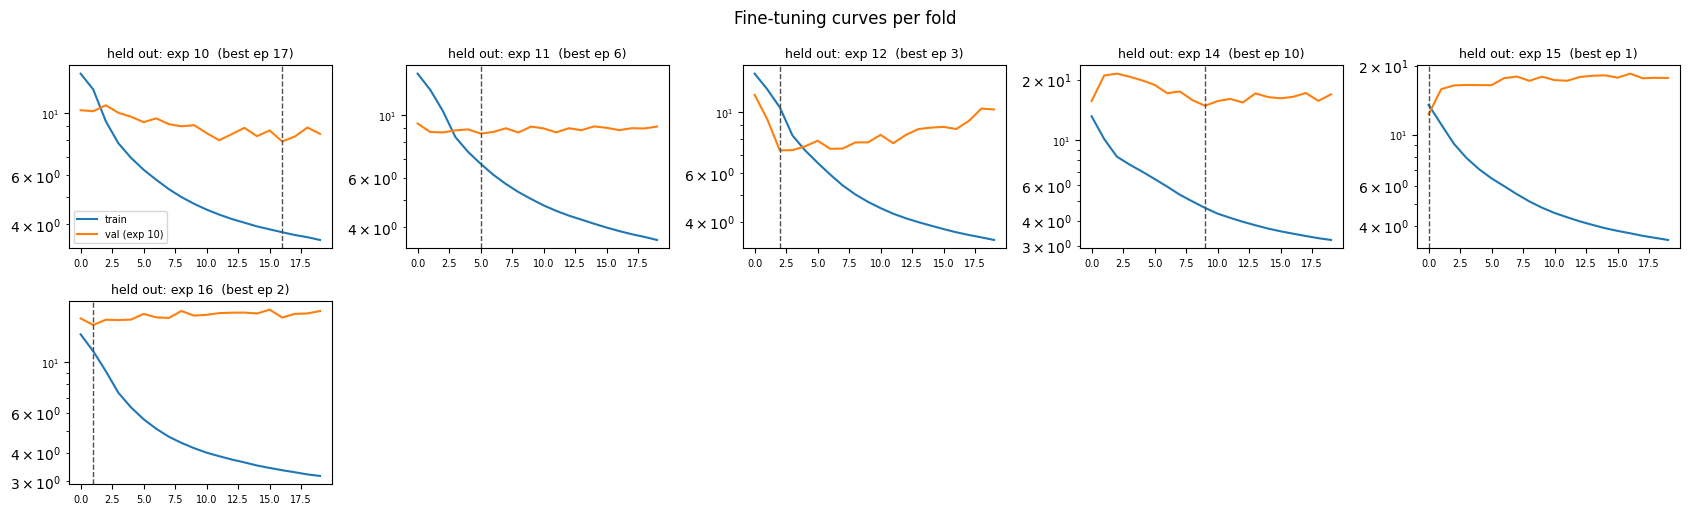

In [16]:
device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available()         else
    "cpu"
)

folds = {}
for e in manifest["folds"]:
    r = manifest["results"].get(str(e), {})
    if EVAL_EXPERIMENTS is not None and e not in EVAL_EXPERIMENTS:
        continue
    if r.get("status") != "done":
        print(f"[skip] exp {e}: {r.get('status', 'pending')}")
        continue
    with open(os.path.join(LOO_DIR, r["config"])) as f:
        cfg = json.load(f)
    folds[e] = dict(cfg=cfg, ckpt_path=os.path.join(LOO_DIR, r["checkpoint"]))

if EVAL_EXPERIMENTS is not None:
    _missing = sorted(set(EVAL_EXPERIMENTS) - set(manifest["folds"]))
    if _missing:
        print(f"[warn] EVAL_EXPERIMENTS not in this LOO run: {_missing}")
assert folds, "no finished fold selected"
FOLD_EXPS = sorted(folds)

# All folds must read the same data with the same features, so the dataset is loaded once.
_FLAGS = ["dataset", "no_alpha", "include_avgv", "no_positions", "pos_frame", "run_mode", "experiments"]
train_args = dict(folds[FOLD_EXPS[0]]["cfg"]["args"])
for e in FOLD_EXPS[1:]:
    a = folds[e]["cfg"]["args"]
    diff = {k: (train_args.get(k), a.get(k)) for k in _FLAGS if train_args.get(k) != a.get(k)}
    assert not diff, f"fold {e} uses different data settings: {diff}"
DATASET_PATH = train_args["dataset"]

if PRED_MAX_CM == "auto":
    _clips = sorted({folds[e]["cfg"]["args"]["dist_clip"] for e in FOLD_EXPS})
    if len(_clips) > 1:
        print(f"[warn] folds use different dist_clip values {_clips}; using the largest")
    PRED_MAX_CM = float(_clips[-1]) - 100.0
    print(f"PRED_MAX_CM = dist_clip − 50 = {PRED_MAX_CM:.0f} cm")
print(f"{len(FOLD_EXPS)} folds: {FOLD_EXPS}   device: {device}")

# Training curves, one panel per fold
ncols = 5
nrows = int(np.ceil(len(FOLD_EXPS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.6 * nrows), squeeze=False)
for ax, e in zip(axes.ravel(), FOLD_EXPS):
    c = folds[e]["cfg"]
    ax.plot(c["train_losses"], lw=1.5, label="train")
    ax.plot(c["val_losses"], lw=1.5, label=f"val (exp {e})")
    ax.axvline(c["best_epoch"] - 1, color="0.3", ls="--", lw=1)
    ax.set_yscale("log"); ax.set_title(f"held out: exp {e}  (best ep {c['best_epoch']})", fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(FOLD_EXPS):]:
    ax.axis("off")
axes[0][0].legend(fontsize=7)
fig.suptitle("Fine-tuning curves per fold"); plt.tight_layout(); plt.show()

## Load data and run every fold model on its held-out experiment

Each fold's `_split.csv` is read back and checked: its val side must be exactly the
held-out experiment. Features are scaled with the scalers stored in that fold's
checkpoint (the pretrained ones unless the run used `--refit_scalers`).

In [17]:
%%time
(X_raw, Y_dists, Y_angles, centroids, poses,
 n_pairs, n_freq, meta_df, feature_slices) = load_for_args(train_args)
EXP = meta_df["experiment"].to_numpy()


def scale(X, scalers):
    # Apply the per-feature-group StandardScalers (same as train_cluster.preprocess)
    Xs = X.reshape(-1, X.shape[2]).copy()
    for name, sl in feature_slices.items():
        Xs[:, sl] = scalers[f"x_{name}"].transform(Xs[:, sl])
    return Xs.reshape(X.shape).astype(np.float32)


@torch.no_grad()
def predict(model, X, batch=1024):
    # Batched forward pass → (pred_dists [cm], pred_angles [deg])
    outs_d, outs_a = [], []
    for i in range(0, len(X), batch):
        xb = torch.from_numpy(np.ascontiguousarray(X[i:i + batch])).to(device)
        pd_, pa_ = model(xb, None)
        outs_d.append(pd_.cpu().numpy()); outs_a.append(pa_.cpu().numpy())
    return np.concatenate(outs_d), np.concatenate(outs_a)


parts, train_parts = [], []
for e in FOLD_EXPS:
    cfg  = folds[e]["cfg"]
    ckpt = torch.load(folds[e]["ckpt_path"], map_location=device, weights_only=False)
    model = TagPairTransformer(**cfg["model_config"])
    model.load_state_dict(ckpt["model_state_dict"])
    model.to(device).eval()

    tr_idx, va_idx = load_split(os.path.join(LOO_DIR, cfg["split_file"]), meta_df)
    assert set(EXP[va_idx]) == {e} and e not in set(EXP[tr_idx]), f"fold {e}: split is not leave-{e}-out"
    assert (len(tr_idx), len(va_idx)) == (cfg["n_train"], cfg["n_val"]), f"fold {e}: sample counts differ"

    sc = scalers_from_checkpoint(ckpt)
    p_d, p_a = predict(model, scale(X_raw[va_idx], sc))
    parts.append(dict(idx=va_idx, pred_d=p_d, pred_a=p_a,
                      base_d=np.broadcast_to(Y_dists[tr_idx].mean(axis=0), p_d.shape)))
    if EVAL_TRAIN_SPLIT:
        t_d, t_a = predict(model, scale(X_raw[tr_idx], sc))
        train_parts.append(dict(fold=e, idx=tr_idx, pred_d=t_d, pred_a=t_a))
    print(f"exp {e:>2}: {len(va_idx):>5} held-out samples   train {len(tr_idx)}")
    del model, ckpt

# Stack the held-out predictions of all folds — one row per sample of the dataset
# that was held out (each sample is held out in exactly one fold).
idx    = np.concatenate([p["idx"] for p in parts])
pred_d = np.concatenate([p["pred_d"] for p in parts])
pred_a = np.concatenate([p["pred_a"] for p in parts])
base_d = np.concatenate([p["base_d"] for p in parts])
true_d, true_a = Y_dists[idx], Y_angles[idx]
meta   = meta_df.iloc[idx].reset_index(drop=True)
meta.insert(0, "sample_idx", idx)
col    = meta["experiment"].to_numpy()
gt_centers, gt_poses = centroids[idx], poses[idx]
if PRED_MAX_CM is not None:
    pred_d = np.where(pred_d > PRED_MAX_CM, np.nan, pred_d)
print(f"\nheld-out predictions: {len(idx)} samples from {len(FOLD_EXPS)} folds")

[loader] cached parse: /home/manaj/RFImaging/multitag/cluster_features_K10_P1_new.parsed.npz
[loader] dropped 3807 rows with NaN/inf (missed rays or missing links)
[loader] 21615 sub-clusters × 3 run(s) → 61038 samples, n_pairs=45, n_freq=22, feat_dim=50, experiments=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
exp 10:  9009 held-out samples   train 52029
exp 11:  9009 held-out samples   train 52029
exp 12:  9009 held-out samples   train 52029
exp 14:  9009 held-out samples   train 52029
exp 15:  5250 held-out samples   train 55788
exp 16:  9009 held-out samples   train 52029

held-out predictions: 50295 samples from 6 folds
CPU times: user 5.67 s, sys: 495 ms, total: 6.16 s
Wall time: 5.39 s


## Metrics

Distances in **cm**, angles in **degrees**. Same definitions as `ETF_eval_master`,
except that the constant baseline is per fold: the mean training target of the
*other* experiments, i.e. what a model that ignores the RF input would predict for
the held-out room. `pretrained_cm` is the checkpoint before fine-tuning, scored
on the same held-out experiment (from the fold config).

Two averages: **ALL (pooled)** weighs every sample equally, so large experiments
dominate; **MEAN (per exp)** weighs every experiment equally.

In [18]:
PLOT_MAX    = float(np.ceil(np.nanmax(true_d) / 50.0) * 50.0)   # cm
DIST_LIM    = (0.0, PLOT_MAX + 100.0)                           # cm
ANGLE_LIM   = (-90.0, 90.0)
WALL_LABELS = ["N", "S", "E", "W"]

# One fixed colour + marker per experiment (keyed by experiment id, so filtering
# never repaints). 13 experiments exceed a safe hue count, hence the marker too.
ALL_EXPS   = sorted(np.unique(EXP).tolist())
# Saturated, high-contrast colours; the most vivid ones go to exps 9–13.
_PALETTE  = {1: "#4363d8", 2: "#3cb44b", 3: "#911eb4", 4: "#9a6324", 5: "#469990",
             6: "#800000", 7: "#000075", 8: "#808000", 9: "#ffb000", 10: "#00b8d4",
             11: "#e6194b", 12: "#f58231", 13: "#f032e6"}
_EXTRA    = ["#000000", "#ff4500", "#2e8b57", "#1e90ff", "#c71585"]   # experiments beyond 13
EXP_COLORS  = {e: _PALETTE.get(e, _EXTRA[i % len(_EXTRA)]) for i, e in enumerate(ALL_EXPS)}
_markers    = ["o", "s", "^", "D", "v", "H", "X", "<", ">", "p", "h", "*", "d"]   # no "P": invisible at small size with lw=0
EXP_MARKERS = {e: _markers[i % len(_markers)] for i, e in enumerate(ALL_EXPS)}


def _vert(m):
    return m[[f"wall_vertical_{w}" for w in WALL_LABELS]].to_numpy().astype(bool)


def metrics_for(p_d, t_d, p_a, t_a, vert, b_d) -> dict:
    err_d = p_d - t_d
    abs_d = np.abs(err_d)
    abs_a = np.abs(p_a - t_a)
    m = {
        "n":             len(t_d),
        "mae_dist_cm":   float(np.nanmean(abs_d)),
        "medae_dist_cm": float(np.nanmedian(abs_d)),
        "p90_dist_cm":   float(np.nanpercentile(abs_d, 90)),
        "rmse_dist_cm":  float(np.sqrt(np.nanmean(err_d ** 2))),
        "bias_dist_cm":  float(np.nanmean(err_d)),
        "acc<=20cm":     float(np.nanmean(abs_d <= 20)),
        "acc<=50cm":     float(np.nanmean(abs_d <= 50)),
        "%oor":          float(100.0 * np.nanmean((p_d < DIST_LIM[0]) | (p_d > DIST_LIM[1]))),
        "gt_dist_cm":    float(np.nanmean(t_d)),
        "baseline_cm":   float(np.nanmean(np.abs(t_d - b_d))),
        "mae_angle_deg": float(np.nanmean(abs_a)),
        "mae_angle_vert_deg": float(np.nanmean(abs_a[vert])) if vert.any() else np.nan,
    }
    m["gain_cm"] = m["baseline_cm"] - m["mae_dist_cm"]
    for i, w in enumerate(WALL_LABELS):
        m[f"mae_{w}_cm"] = float(np.nanmean(abs_d[:, i]))
    return m


vert = _vert(meta)
rows = {}
for e in FOLD_EXPS:
    s = col == e
    rows[e] = metrics_for(pred_d[s], true_d[s], pred_a[s], true_a[s], vert[s], base_d[s])
    pre = folds[e]["cfg"].get("pretrained_metrics") or {}
    rows[e]["pretrained_cm"]  = 100 * pre.get("mae_dist_m", np.nan)
    rows[e]["pretrained_deg"] = pre.get("mae_angle_deg", np.nan)
    rows[e]["best_epoch"]     = folds[e]["cfg"]["best_epoch"]
loo_tbl = pd.DataFrame(rows).T
loo_tbl["ft_gain_cm"] = loo_tbl["pretrained_cm"] - loo_tbl["mae_dist_cm"]

pooled = metrics_for(pred_d, true_d, pred_a, true_a, vert, base_d)
_w = loo_tbl["n"].to_numpy(float)
pooled["pretrained_cm"]  = float(np.average(loo_tbl["pretrained_cm"], weights=_w))
pooled["pretrained_deg"] = float(np.average(loo_tbl["pretrained_deg"], weights=_w))
pooled["ft_gain_cm"]     = pooled["pretrained_cm"] - pooled["mae_dist_cm"]
mean_row = loo_tbl.mean(numeric_only=True)
mean_row["n"] = loo_tbl["n"].sum()
loo_tbl.loc["ALL (pooled)"]  = pd.Series(pooled)
loo_tbl.loc["MEAN (per exp)"] = mean_row

_cols = ["n", "mae_dist_cm", "pretrained_cm", "ft_gain_cm", "baseline_cm", "gain_cm",
         "medae_dist_cm", "p90_dist_cm", "rmse_dist_cm", "bias_dist_cm",
         "acc<=20cm", "acc<=50cm", "%oor", "gt_dist_cm",
         "mae_angle_deg", "pretrained_deg", "mae_angle_vert_deg", "best_epoch"]
_fmt = {c: "{:.2f}" for c in _cols}
_fmt |= {"n": "{:.0f}", "best_epoch": "{:.0f}", "acc<=20cm": "{:.1%}", "acc<=50cm": "{:.1%}",
         "gain_cm": "{:+.2f}", "ft_gain_cm": "{:+.2f}"}
display(loo_tbl[_cols].style.format(_fmt, na_rep="")
        .background_gradient(subset=pd.IndexSlice[FOLD_EXPS, "mae_dist_cm"], cmap="RdYlGn_r")
        .background_gradient(subset=pd.IndexSlice[FOLD_EXPS, "ft_gain_cm"], cmap="RdYlGn")
        .set_caption("Leave-one-experiment-out: each row is scored by the model that never saw it  "
                     "(ft_gain = pretrained − fine-tuned, gain = constant baseline − fine-tuned)"))

m = loo_tbl.loc["MEAN (per exp)"]
print(f"LOO MAE dist : {pooled['mae_dist_cm']:.1f} cm pooled, {m['mae_dist_cm']:.1f} cm per-exp mean  "
      f"(pretrained {m['pretrained_cm']:.1f}, constant {m['baseline_cm']:.1f})")
print(f"LOO MAE angle: {pooled['mae_angle_deg']:.2f}° pooled, {m['mae_angle_deg']:.2f}° per-exp mean  "
      f"(pretrained {m['pretrained_deg']:.2f}°)")
print(f"fine-tuning helped on {(loo_tbl.loc[FOLD_EXPS, 'ft_gain_cm'] > 0).sum()} / {len(FOLD_EXPS)} "
      f"held-out experiments; beat the constant on {(loo_tbl.loc[FOLD_EXPS, 'gain_cm'] > 0).sum()}")

,n,mae_dist_cm,pretrained_cm,ft_gain_cm,baseline_cm,gain_cm,medae_dist_cm,p90_dist_cm,rmse_dist_cm,bias_dist_cm,acc<=20cm,acc<=50cm,%oor,gt_dist_cm,mae_angle_deg,pretrained_deg,mae_angle_vert_deg,best_epoch
10,9009,102.84,261.34,+158.50,109.22,+6.38,84.81,212.11,130.18,-101.72,3.2%,13.6%,0.00,402.79,18.47,23.20,18.45,17
11,9009,103.17,241.08,+137.91,130.34,+27.17,67.65,268.25,146.80,-96.62,5.5%,17.2%,0.00,383.99,22.60,22.74,22.65,6
12,9009,50.56,236.21,+185.65,166.36,+115.80,34.80,86.38,82.68,6.99,11.4%,25.5%,0.00,371.75,23.46,25.92,23.68,3
14,9009,186.55,237.89,+51.33,190.40,+3.85,155.96,398.58,232.49,-110.47,2.9%,7.2%,0.00,361.99,34.09,31.76,34.80,10
15,5250,149.90,224.52,+74.61,129.29,-20.61,136.84,229.39,158.40,-49.43,0.1%,0.2%,0.00,368.32,20.73,19.83,21.48,1
16,9009,127.88,216.40,+88.52,217.07,+89.18,102.71,276.84,162.68,-6.13,1.7%,5.3%,0.00,325.00,26.82,30.69,27.18,2
ALL (pooled),50295,113.22,237.12,+123.89,159.19,+45.97,79.54,277.75,154.96,-67.74,4.5%,12.3%,0.00,369.02,24.64,26.13,24.98,
MEAN (per exp),50295,120.15,236.24,+116.09,157.11,+36.96,97.13,245.26,152.21,-59.56,4.1%,11.5%,0.00,368.97,24.36,25.69,24.71,6


LOO MAE dist : 113.2 cm pooled, 120.2 cm per-exp mean  (pretrained 236.2, constant 157.1)
LOO MAE angle: 24.64° pooled, 24.36° per-exp mean  (pretrained 25.69°)
fine-tuning helped on 6 / 6 held-out experiments; beat the constant on 5


### Ranking chart

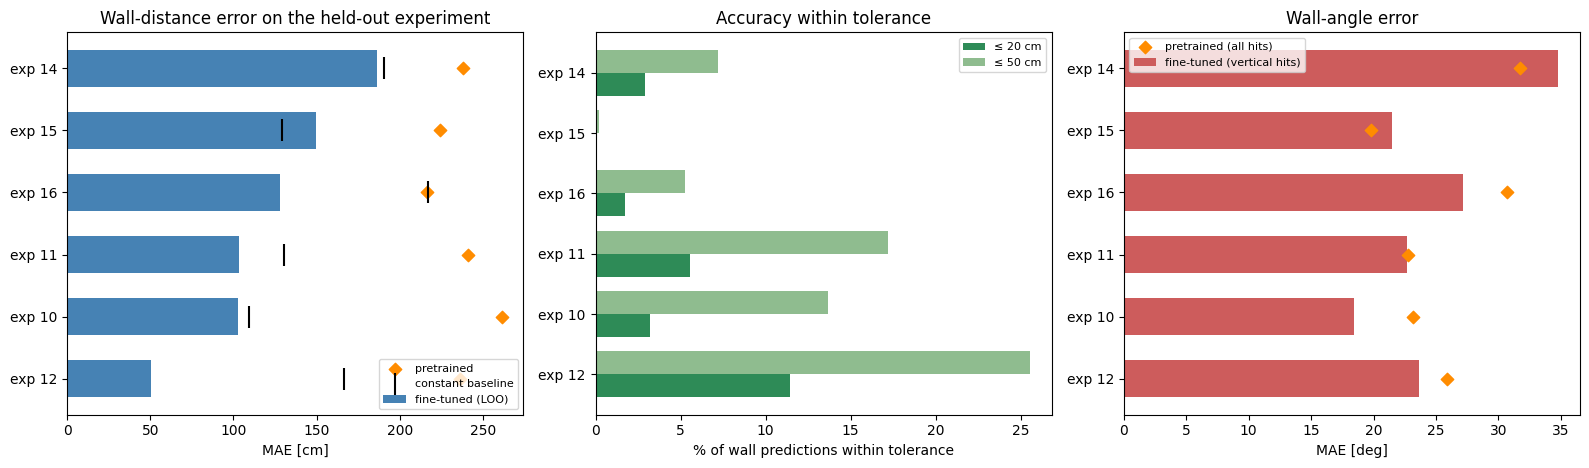

In [19]:
plot_tbl = loo_tbl.loc[FOLD_EXPS].sort_values("mae_dist_cm")
labels   = [f"exp {e}" for e in plot_tbl.index]
y        = np.arange(len(plot_tbl))
fig, axes = plt.subplots(1, 3, figsize=(16, 0.38 * len(plot_tbl) + 2.5))

ax = axes[0]
ax.barh(y, plot_tbl["mae_dist_cm"], height=0.6, color="steelblue", label="fine-tuned (LOO)")
ax.scatter(plot_tbl["pretrained_cm"], y, marker="D", s=40, color="darkorange", zorder=5,
           label="pretrained")
ax.scatter(plot_tbl["baseline_cm"], y, marker="|", s=250, color="k", zorder=5,
           label="constant baseline")
ax.set_yticks(y, labels)
ax.set_xlabel("MAE [cm]"); ax.set_title("Wall-distance error on the held-out experiment")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
w = 0.38
ax.barh(y - w/2, plot_tbl["acc<=20cm"] * 100, height=w, label="≤ 20 cm", color="seagreen")
ax.barh(y + w/2, plot_tbl["acc<=50cm"] * 100, height=w, label="≤ 50 cm", color="darkseagreen")
ax.set_yticks(y, labels)
ax.set_xlabel("% of wall predictions within tolerance"); ax.set_title("Accuracy within tolerance")
ax.legend(fontsize=8)

ax = axes[2]
ax.barh(y, plot_tbl["mae_angle_vert_deg"], height=0.6, color="indianred", label="fine-tuned (vertical hits)")
ax.scatter(plot_tbl["pretrained_deg"], y, marker="D", s=40, color="darkorange", zorder=5,
           label="pretrained (all hits)")
ax.set_yticks(y, labels)
ax.set_xlabel("MAE [deg]"); ax.set_title("Wall-angle error"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

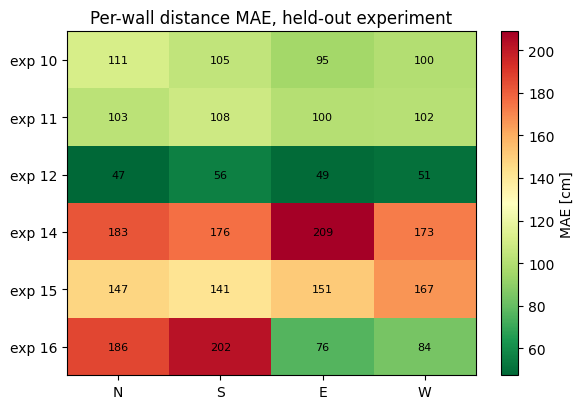

In [20]:
# Per-wall MAE — held-out experiment × {N,S,E,W}
wall_mat = loo_tbl.loc[FOLD_EXPS, [f"mae_{w}_cm" for w in WALL_LABELS]].astype(float)
fig, ax = plt.subplots(figsize=(6, 0.4 * len(wall_mat) + 1.8))
im = ax.imshow(wall_mat.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(4), WALL_LABELS)
ax.set_yticks(range(len(wall_mat)), [f"exp {e}" for e in wall_mat.index])
for i in range(wall_mat.shape[0]):
    for j in range(wall_mat.shape[1]):
        ax.text(j, i, f"{wall_mat.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="MAE [cm]")
ax.set_title("Per-wall distance MAE, held-out experiment")
plt.tight_layout(); plt.show()

### Prediction vs ground truth, per held-out experiment

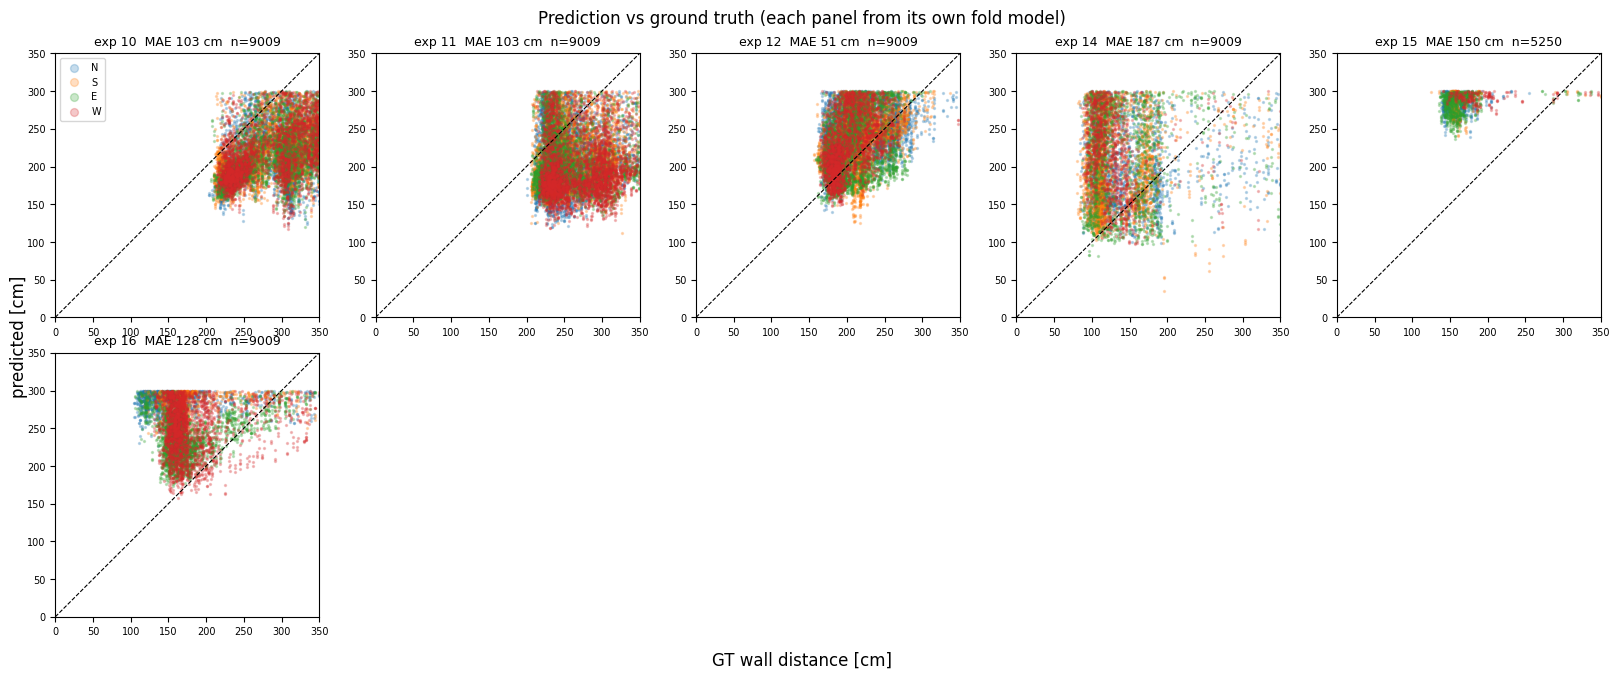

In [21]:
ncols = 5
nrows = int(np.ceil(len(FOLD_EXPS) / ncols))
lim_d = (0, PRED_MAX_CM + 50 if PRED_MAX_CM is not None else PLOT_MAX)   # cm
fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.4 * nrows), squeeze=False)
for ax, e in zip(axes.ravel(), FOLD_EXPS):
    s = col == e
    for i, wl in enumerate(WALL_LABELS):
        ax.scatter(true_d[s, i], np.clip(pred_d[s, i], *lim_d), s=2, alpha=0.25, label=wl)
    ax.plot(lim_d, lim_d, "k--", lw=0.8)
    ax.set_xlim(lim_d); ax.set_ylim(lim_d); ax.set_aspect("equal")
    ax.set_title(f"exp {e}  MAE {loo_tbl.loc[e, 'mae_dist_cm']:.0f} cm  n={int(loo_tbl.loc[e, 'n'])}",
                 fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(FOLD_EXPS):]:
    ax.axis("off")
axes[0][0].legend(fontsize=7, markerscale=4)
fig.supxlabel("GT wall distance [cm]"); fig.supylabel("predicted [cm]")
plt.suptitle("Prediction vs ground truth (each panel from its own fold model)")
plt.tight_layout(); plt.show()

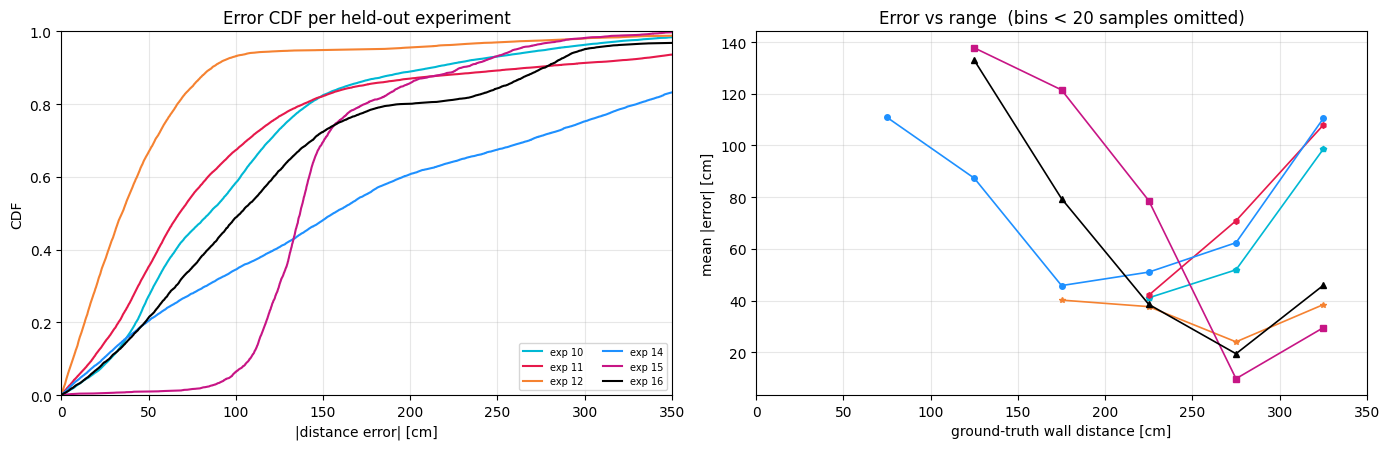

In [22]:
LIM_CM = PRED_MAX_CM + 50 if PRED_MAX_CM is not None else PLOT_MAX   # cm, x-axis limit
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
for e in FOLD_EXPS:
    err = np.sort(np.abs(pred_d[col == e] - true_d[col == e]).ravel())
    err = err[np.isfinite(err)]
    ax.plot(err, np.arange(1, len(err) + 1) / len(err), lw=1.5, color=EXP_COLORS[e], label=f"exp {e}")
ax.set_xlim(0, LIM_CM); ax.set_ylim(0, 1)
ax.set_xlabel("|distance error| [cm]"); ax.set_ylabel("CDF")
ax.set_title("Error CDF per held-out experiment"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)

ax = axes[1]
BIN_EDGES = np.arange(0, LIM_CM + 1, 50)
centers_b = 0.5 * (BIN_EDGES[:-1] + BIN_EDGES[1:])
for e in FOLD_EXPS:
    gt  = true_d[col == e].ravel()
    err = np.abs(pred_d[col == e] - true_d[col == e]).ravel()
    b   = np.digitize(gt, BIN_EDGES) - 1
    means = [np.nanmean(err[b == k]) if (b == k).sum() >= 20 else np.nan for k in range(len(centers_b))]
    ax.plot(centers_b, means, marker=EXP_MARKERS[e], ms=4, lw=1.2, color=EXP_COLORS[e], label=f"exp {e}")
ax.set_xlabel("ground-truth wall distance [cm]"); ax.set_ylabel("mean |error| [cm]")
ax.set_xlim(0, LIM_CM); ax.set_title("Error vs range  (bins < 20 samples omitted)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Train-split accuracy per fold (optional)

With `EVAL_TRAIN_SPLIT = True`, each fold model is also scored on its own train
split (all other experiments): the gap to the held-out MAE is the cost of moving to
an unseen deployment.

In [23]:
if EVAL_TRAIN_SPLIT:
    rows_tr = {}
    for p in train_parts:
        i = p["idx"]
        rows_tr[p["fold"]] = metrics_for(p["pred_d"], Y_dists[i], p["pred_a"], Y_angles[i],
                                         _vert(meta_df.iloc[i]), Y_dists[i].mean(axis=0))
    tr_tbl = pd.DataFrame(rows_tr).T
    gap = pd.DataFrame({"mae_train_cm": tr_tbl["mae_dist_cm"],
                        "mae_heldout_cm": loo_tbl.loc[FOLD_EXPS, "mae_dist_cm"]}).astype(float)
    gap["gap_cm"] = gap["mae_heldout_cm"] - gap["mae_train_cm"]
    gap.index.name = "held-out exp"
    display(gap.style.format("{:.2f}").background_gradient(subset=["gap_cm"], cmap="RdYlGn_r"))
else:
    gap = None
    print("skipped (EVAL_TRAIN_SPLIT = False)")

skipped (EVAL_TRAIN_SPLIT = False)


## Wall geometry per experiment, local frame (optional)

`visualize_walls3D` for the experiments in `VIZ_EXPERIMENTS`, in that experiment's
own levelled frame: prediction, then ground truth.

In [24]:
_viz_dir = os.path.join(_tc.T2T_ROOT, "MLNotebooks")
if _viz_dir not in sys.path:
    sys.path.insert(0, _viz_dir)
try:
    import vizualizeWalls
    importlib.reload(vizualizeWalls)
    from vizualizeWalls import visualize_walls3D
except ImportError as err:
    visualize_walls3D = None
    print("vizualizeWalls not importable:", err)

pred_d_viz = np.where((pred_d < DIST_LIM[0]) | (pred_d > DIST_LIM[1]), np.nan, pred_d)
for e in [e for e in VIZ_EXPERIMENTS if e in FOLD_EXPS]:
    if visualize_walls3D is None:
        break
    sel = np.flatnonzero(col == e)[:VIZ_LIMIT]
    print(f"[exp {e}] predictions (fold model) — top view:")
    visualize_walls3D(gt_centers[sel], gt_poses[sel], pred_d_viz[sel] / 100.0, pred_a[sel],
                      show_pose_arrow=False, show_centers=True,
                      clamp_to_ground_plane=True, elev=90, azim=-90)
    print(f"[exp {e}] ground truth — top view:")
    visualize_walls3D(gt_centers[sel], gt_poses[sel], true_d[sel] / 100.0, true_a[sel],
                      show_pose_arrow=False, show_centers=True,
                      clamp_to_ground_plane=True, elev=90, azim=-90)

## Room alignment — one coordinate system for all experiments

Every experiment has its own room scan with its own origin and heading, and
`cluster_features.py` levels each one separately, so centroids of different
experiments live in different frames. `room_alignment.py` relates them through the
scans themselves (all show the same walls):

* the levelled frames are all z-up, so experiment *e* maps to the room frame by a
  yaw + translation: `p_room = R_z(yaw_e) · p_levelled + t_e`;
* yaw/xy come from registering each scan's wall points (|n_z| < 0.3) to a reference
  scan — exhaustive 1° yaw search with FFT cross-correlation for the shift, then
  trimmed 2-D ICP from the best few candidates (the near-rectangular room makes
  the 180°-flipped fit the runner-up; ceiling beams and the corner notch decide);
* z: each scan's floor is moved to z = 0;
* the room frame is the reference scan turned so the walls are axis-aligned, with
  the wall bounding box starting at (0, 0).

Computed once (≈ 2 min) and cached as `<dataset>.room_alignment.json` next to the CSV.
`median_resid_cm` is the median distance of an experiment's wall points to the
reference walls after alignment; `runner_up_resid_cm` is the best competing
solution (should be far larger).

In [25]:
%%time
al = ra.load_alignment(DATASET_PATH, ref=ALIGN_REF, recompute=ALIGN_RECOMPUTE)
q = al.quality.copy()
q["yaw_deg"] = [np.degrees(al.yaw[e]) for e in q.index]
q[["tx_m", "ty_m", "tz_m"]] = np.array([al.t[e] for e in q.index])
display(q.style.format("{:.2f}").format({"inlier_10cm": "{:.1%}"})
        .set_caption(f"Scan → room-frame transforms (reference: exp {al.ref})"))
missing = sorted(set(ALL_EXPS) - set(al.experiments))
assert not missing, f"no alignment for experiments {missing}"
al.plot_check(exps=FOLD_EXPS, colors=EXP_COLORS); plt.show()

[align] reading level_rot from /home/manaj/RFImaging/multitag/cluster_features_K10_P1_new.csv
[align] exp  1:  97925 wall points, floor z = -1.093 m
[align] exp  2:  94755 wall points, floor z = -1.417 m
[align] exp  3:  95764 wall points, floor z = -1.180 m
[align] exp  4:  95279 wall points, floor z = -1.264 m
[align] exp  5:  94188 wall points, floor z = -1.283 m
[align] exp  6:  82901 wall points, floor z = -1.155 m
[align] exp  7:  95250 wall points, floor z = -1.221 m
[align] exp  8:  95456 wall points, floor z = -1.259 m
[align] exp  9:  97534 wall points, floor z = -1.224 m
[align] exp 10:  90623 wall points, floor z = -1.205 m
[align] exp 11:  93120 wall points, floor z = -1.131 m
[align] exp 12:  93991 wall points, floor z = -1.133 m
[align] exp 13:  93032 wall points, floor z = -1.264 m


KeyError: '14'

### Transform the samples, and check the data against the room

Centroids are mapped with `to_room`, poses get the experiment's yaw pre-multiplied,
so the N/S/E/W rays (from `room_alignment.wall_ray_dirs`, identical to the ones
`cluster_features.py` cast) turn with them. The check below rebuilds every
ground-truth **vertical** wall hit in the room frame and measures its distance to the
*reference* scan's walls. Each experiment's hits come from its own scan, so a small
distance shows that the alignment and the pose convention are right for the
training data, not just for the meshes.

In [26]:
cent_room = al.to_room_many(col, gt_centers)
pose_room = al.poses_to_room_many(col, gt_poses)
gt_hits   = ra.wall_hit_points(cent_room, pose_room, true_d / 100.0)      # (n, 4, 3) m
pr_hits   = ra.wall_hit_points(cent_room, pose_room, pred_d_viz / 100.0)

ref_tree = ra.cKDTree(al.walls_room[al.ref][:, :2])
chk = {}
for e in FOLD_EXPS:
    s = col == e
    h = gt_hits[s][vert[s]]
    h = h[np.isfinite(h).all(axis=1)]
    d, _ = ref_tree.query(h[:, :2])
    chk[e] = dict(gt_vertical_hits=len(h), median_cm=100 * np.median(d), p90_cm=100 * np.percentile(d, 90))
display(pd.DataFrame(chk).T.style.format({"gt_vertical_hits": "{:.0f}", "median_cm": "{:.1f}",
                                         "p90_cm": "{:.1f}"})
        .set_caption(f"GT wall hits (room frame) → distance to exp {al.ref}'s walls"))

NameError: name 'al' is not defined

### All experiments in one room — centroids

Every sub-cluster centroid of every experiment, in the room frame, one colour +
marker per experiment, on the reference scan's walls (grey). The crosses are the
tag positions of each experiment.

[loader] cached parse: /home/manaj/RFImaging/multitag/cluster_features_K10_P1.parsed.npz


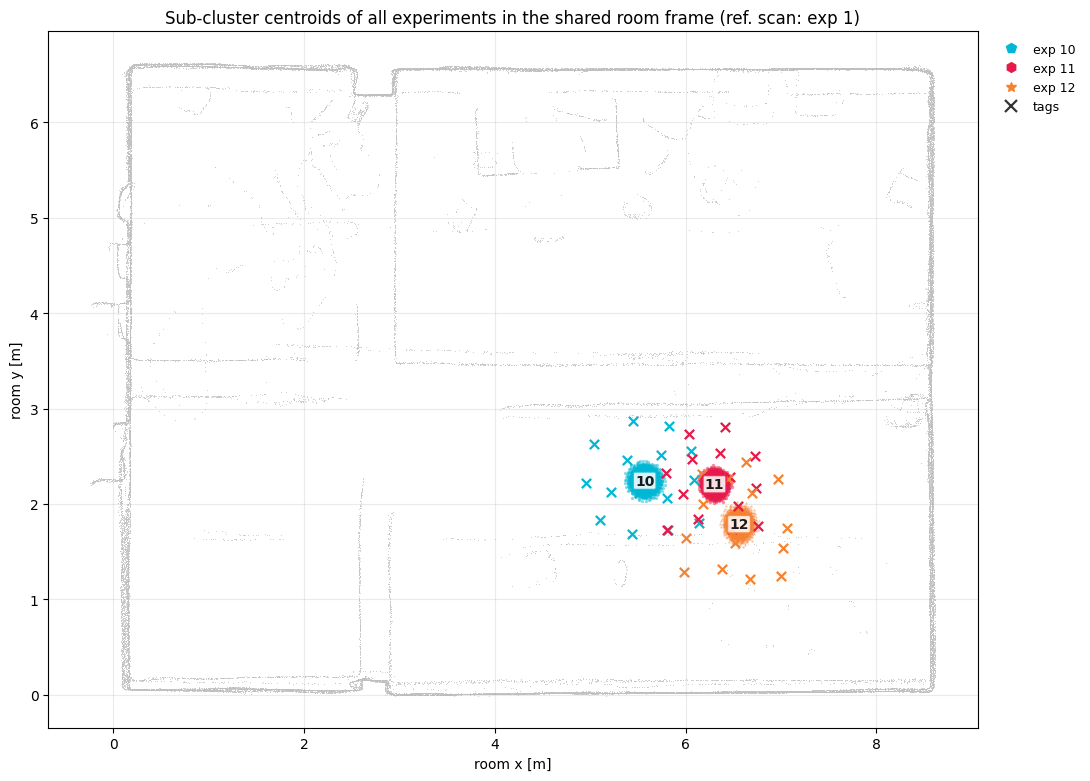

In [ ]:
raw = _tc._read_raw(DATASET_PATH)        # cached parse — tag positions per sub-cluster
outline = al.room_outline()

fig, ax = plt.subplots(figsize=(11, 11))
ax.scatter(outline[:, 0], outline[:, 1], s=0.3, c="0.75", lw=0, zorder=1)
for e in FOLD_EXPS:
    s = EXP == e
    c = al.to_room(e, np.unique(centroids[s], axis=0))
    ax.scatter(c[:, 0], c[:, 1], s=7, alpha=0.5, lw=0, marker=EXP_MARKERS[e],
               color=EXP_COLORS[e], zorder=3)
    tags = np.unique(raw["tag_xyz"][raw["keys"][:, 0] == e].reshape(-1, 3).round(4), axis=0)
    t = al.to_room(e, tags)
    ax.scatter(t[:, 0], t[:, 1], s=45, marker="x", lw=1.6, color=EXP_COLORS[e], zorder=4)
    mc = c.mean(axis=0)
    ax.annotate(f"{e}", mc[:2], fontsize=10, fontweight="bold", ha="center", va="center",
                color="0.1", zorder=5,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=EXP_COLORS[e], lw=1.5, alpha=0.85))
handles = [Line2D([], [], ls="", marker=EXP_MARKERS[e], color=EXP_COLORS[e], ms=7, label=f"exp {e}")
           for e in FOLD_EXPS]
handles.append(Line2D([], [], ls="", marker="x", color="0.2", ms=8, mew=1.6, label="tags"))
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9, frameon=False)
ax.set_aspect("equal"); ax.grid(alpha=0.25)
ax.set_xlabel("room x [m]"); ax.set_ylabel("room y [m]")
ax.set_title(f"Sub-cluster centroids of all experiments in the shared room frame (ref. scan: exp {al.ref})")
plt.tight_layout(); plt.show()

### All experiments in one room — wall hits, ground truth vs LOO prediction

The same frame, with each sub-cluster's four wall hits: left the ground truth,
right the prediction of the fold model that never saw that experiment. Up to
`MERGED_LIMIT` sub-clusters per experiment (one run each). Where the predicted
points of different experiments land on the same grey wall, the models agree on
the room even though each was evaluated on a deployment it had not seen.

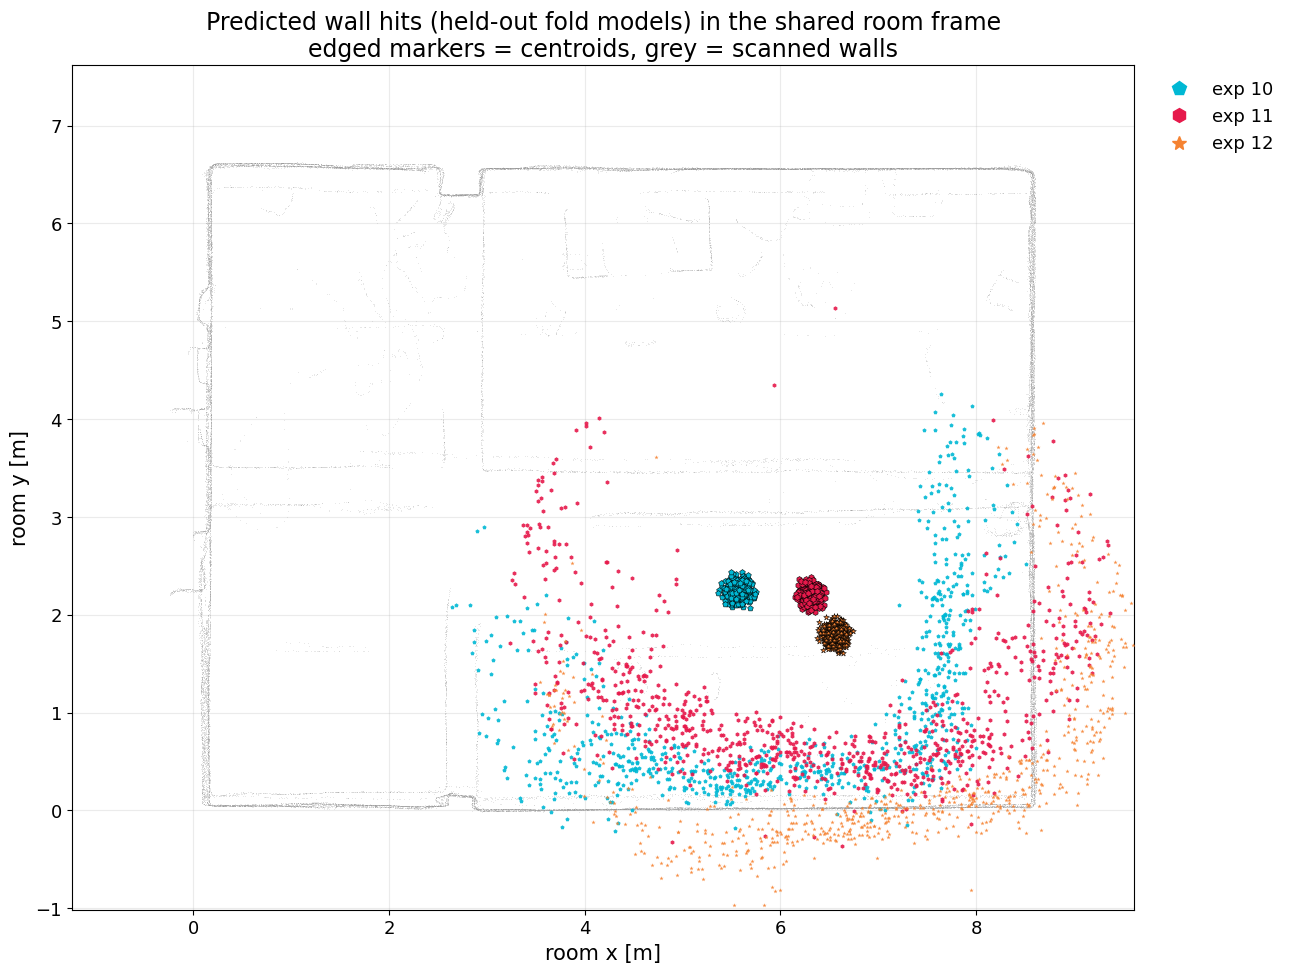

In [ ]:
rng = np.random.default_rng(0)
first_run = ~meta.duplicated(SUB_KEYS).to_numpy()          # one sample per sub-cluster
pick = {}
for e in FOLD_EXPS:
    cand = np.flatnonzero((col == e) & first_run)
    pick[e] = rng.choice(cand, min(MERGED_LIMIT, len(cand)), replace=False)

fig, ax = plt.subplots(figsize=(13, 11))
ax.scatter(outline[:, 0], outline[:, 1], s=0.3, c="0.6", alpha=0.25, lw=0, zorder=1)   # scan walls
for e in FOLD_EXPS:
    h = pr_hits[pick[e]].reshape(-1, 3)
    ax.scatter(h[:, 0], h[:, 1], s=10, alpha=0.9, lw=0, marker=EXP_MARKERS[e],
               color=EXP_COLORS[e], zorder=3)
    cc = cent_room[pick[e]]
    ax.scatter(cc[:, 0], cc[:, 1], s=18, marker=EXP_MARKERS[e], color=EXP_COLORS[e],
               edgecolor="k", lw=0.4, zorder=4)
ax.set_aspect("equal"); ax.grid(alpha=0.25)
ax.set_xlabel("room x [m]", fontsize=15); ax.set_ylabel("room y [m]", fontsize=15)
ax.tick_params(labelsize=13)
_pad = 1.0
_x, _y = outline[:, 0], outline[:, 1]
ax.set_xlim(_x.min() - _pad, _x.max() + _pad); ax.set_ylim(_y.min() - _pad, _y.max() + _pad)
ax.legend(handles=[Line2D([], [], ls="", marker=EXP_MARKERS[e], color=EXP_COLORS[e], ms=10,
                          label=f"exp {e}") for e in FOLD_EXPS],
          loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=13, frameon=False)
ax.set_title("Predicted wall hits (held-out fold models) in the shared room frame\n"
             "edged markers = centroids, grey = scanned walls", fontsize=17)
plt.tight_layout(); plt.show()

### Where in the room is the model wrong?

Sub-cluster centroids coloured by their mean absolute wall-distance error (held-out
fold model, all runs of the sub-cluster averaged). Marker shape = experiment.

/tmp/ipykernel_11273/729096606.py:3: RuntimeWarning: Mean of empty slice
  "err": np.nanmean(np.abs(pred_d - true_d), axis=1),


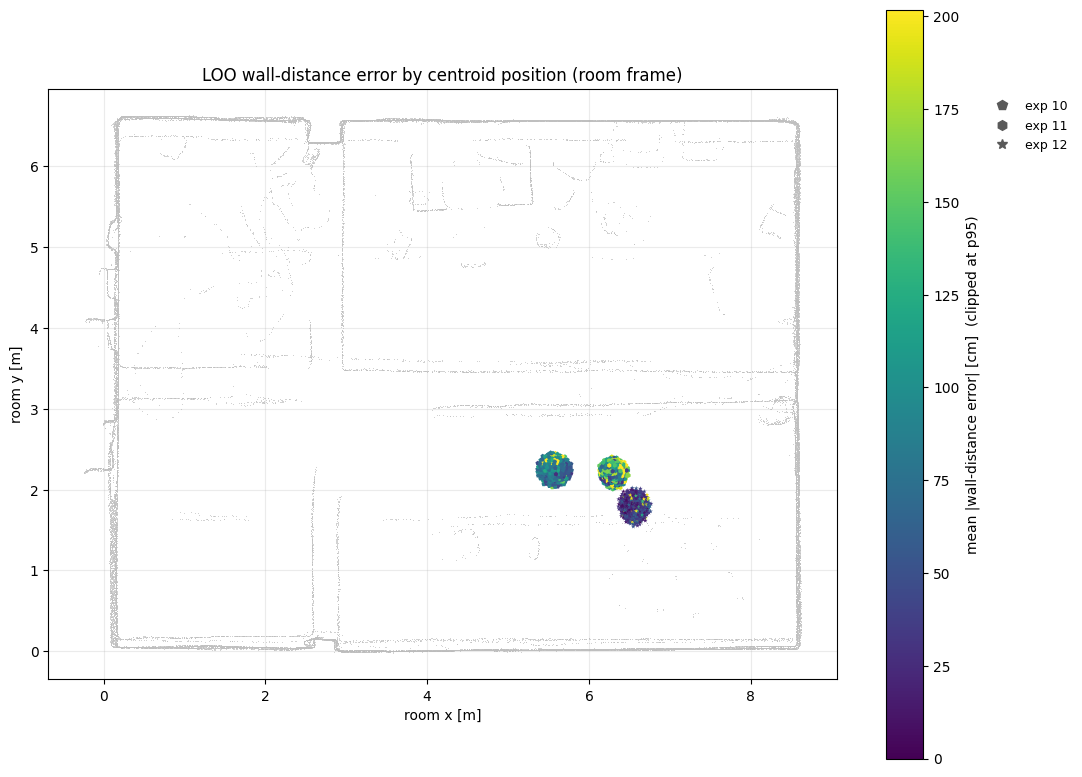

In [ ]:
err_sub = (pd.DataFrame({"experiment": col, "combination_id": meta["combination_id"],
                         "permutation_id": meta["permutation_id"],
                         "err": np.nanmean(np.abs(pred_d - true_d), axis=1),
                         "x": cent_room[:, 0], "y": cent_room[:, 1]})
           .groupby(SUB_KEYS, as_index=False).mean())
vmax = float(np.nanpercentile(err_sub["err"], 95))

fig, ax = plt.subplots(figsize=(11, 11))
ax.scatter(outline[:, 0], outline[:, 1], s=0.3, c="0.75", lw=0, zorder=1)
for e in FOLD_EXPS:
    s = err_sub["experiment"] == e
    sc = ax.scatter(err_sub.loc[s, "x"], err_sub.loc[s, "y"], c=err_sub.loc[s, "err"],
                    cmap="viridis", vmin=0, vmax=vmax, s=12, marker=EXP_MARKERS[e], lw=0, zorder=3)
plt.colorbar(sc, ax=ax, shrink=0.7, label="mean |wall-distance error| [cm]  (clipped at p95)")
ax.legend(handles=[Line2D([], [], ls="", marker=EXP_MARKERS[e], color="0.35", ms=7, label=f"exp {e}")
                   for e in FOLD_EXPS],
          loc="upper left", bbox_to_anchor=(1.18, 1), fontsize=9, frameon=False)
ax.set_aspect("equal"); ax.grid(alpha=0.25)
ax.set_xlabel("room x [m]"); ax.set_ylabel("room y [m]")
ax.set_title("LOO wall-distance error by centroid position (room frame)")
plt.tight_layout(); plt.show()

## Export

In [ ]:
out_csv = os.path.join(LOO_DIR, "loo_perexp_eval.csv")
export = loo_tbl.copy()
if gap is not None:
    export = export.join(gap[["mae_train_cm", "gap_cm"]], how="left")
export.index.name = "experiment"
export.to_csv(out_csv)
print(f"Per-experiment LOO metrics → {out_csv}")

# Per-sample held-out predictions, keyed like _split.csv, with room-frame geometry
pred_csv = os.path.join(LOO_DIR, "loo_val_predictions.csv")
_p = meta[["sample_idx"] + SUB_KEYS + ["run", "csv_rows"]].copy()
_p[["centroid_room_x", "centroid_room_y", "centroid_room_z"]] = cent_room
for j, wl in enumerate(WALL_LABELS):
    _p[f"gt_dist_{wl}_cm"], _p[f"pred_dist_{wl}_cm"] = true_d[:, j], pred_d[:, j]
    _p[f"gt_angle_{wl}_deg"], _p[f"pred_angle_{wl}_deg"] = true_a[:, j], pred_a[:, j]
_p.to_csv(pred_csv, index=False)
print(f"Held-out predictions       → {pred_csv}")

Per-experiment LOO metrics → /home/manaj/RFImaging/multitag_ml_training/Saved/finetune_1014235445/loo_perexp_eval.csv


Held-out predictions       → /home/manaj/RFImaging/multitag_ml_training/Saved/finetune_1014235445/loo_val_predictions.csv
